# Sequential experiments on running counts

Lindon & Malek (2022), *Anytime-Valid Inference for Multinomial Count Data* (NeurIPS), give a sequential test
for experiments with count outcomes such as conversions or errors. The test can be checked after every event
while keeping the type-I error at or below a chosen level $u$. Such a test is called anytime-valid.

The test statistic is a Dirichlet–multinomial Bayes factor. Let $\boldsymbol\theta_0$ be the share of events
each arm should receive under the null, $\boldsymbol\alpha_0$ the parameters of a Dirichlet mixing
distribution, and $\mathbf S_n$ the running count of events in each arm after $n$ events. Their Eq. 3 is

$$BF_{10}(\mathbf x_{1:n}) = \frac{\mathrm{B}(\boldsymbol\alpha_0 + \mathbf S_n)}{\mathrm B(\boldsymbol\alpha_0)}\,
\frac{1}{\boldsymbol\theta_0^{\mathbf S_n}},$$

where $\mathrm B$ is the multivariate Beta function. The event stream enters only through $\mathbf S_n$. Two
consequences follow:

1. Updating the test after an event means adding one to one count.
2. A shared time-varying baseline does not need to be modelled. If each arm's events arrive as a Poisson
   process with intensity $\rho_a\,\lambda(t)$, then given that an event occurred, the arm it came from is
   $\text{Multinomial}(1, \boldsymbol\theta)$ with $\theta_a \propto \rho_a$. The baseline $\lambda(t)$ cancels.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy.special import gammaln
from scipy import stats

rng = np.random.default_rng(202)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")


def log_mbeta(a):
    return gammaln(a).sum(-1) - gammaln(a.sum(-1))


def log_bf(S, theta0, alpha0):
    return log_mbeta(alpha0 + S) - log_mbeta(alpha0) - (S * np.log(theta0)).sum(-1)

## A three-arm test with a varying baseline

Two weeks of hourly traffic. The shared baseline has a daily cycle, and a promotion triples volume on days 7
and 8. Arm C converts 6% more than control; arm B is identical to control. Traffic is split equally, so
$\boldsymbol\theta_0 = (1/3, 1/3, 1/3)$.

In [2]:
hours = np.arange(24 * 14)
baseline = 80 * (1 + 0.7 * np.sin(2 * np.pi * (hours - 6) / 24))
baseline[(hours >= 24 * 6) & (hours < 24 * 8)] *= 3
rho = np.array([1.00, 1.00, 1.06])                              # control, B, C
theta0 = np.ones(3) / 3

hourly = rng.poisson(baseline[:, None] * rho[None, :])          # (hour, arm) event counts
events = np.concatenate([rng.permutation(np.repeat(np.arange(3), h)) for h in hourly])
S = np.cumsum(np.eye(3, dtype=int)[events], axis=0)            # running counts S_n, shape (n, 3)
print(f"{len(events):,} conversions; final counts {S[-1]}")

106,072 conversions; final counts [34889 34485 36698]


With a uniform mixing distribution $\boldsymbol\alpha_0 = \mathbf 1$ (the paper's default), the sequential
$p$-value is $p_n = \min(p_{n-1}, 1/BF_n)$. Rejecting when $p_n \le u$ has type-I error at most $u$ however
often the test is checked.

In [3]:
alpha0 = np.ones(3)
logbf = log_bf(S, theta0, alpha0)
p_seq = np.minimum.accumulate(np.minimum(1, np.exp(-logbf)))
u = 0.05
stop = int(np.argmax(p_seq <= u)) if (p_seq <= u).any() else None
print("rejected at event", stop, "of", len(events))

rejected at event 24320 of 106072


The closed form uses only $\mathbf S_n$. The paper's recursive form (their Eq. 5) multiplies one bet per event,
using the posterior mean before that event. The two agree to rounding error.

In [4]:
prev = np.vstack([np.zeros(3, int), S[:-1]])
post_mean = (alpha0 + prev) / (alpha0.sum() + np.arange(len(events)))[:, None]
recursive = np.cumsum(np.log(post_mean[np.arange(len(events)), events] / theta0[events]))
print("max |recursive - closed form| =", np.abs(recursive - logbf).max())

max |recursive - closed form| = 5.707825323497673e-10


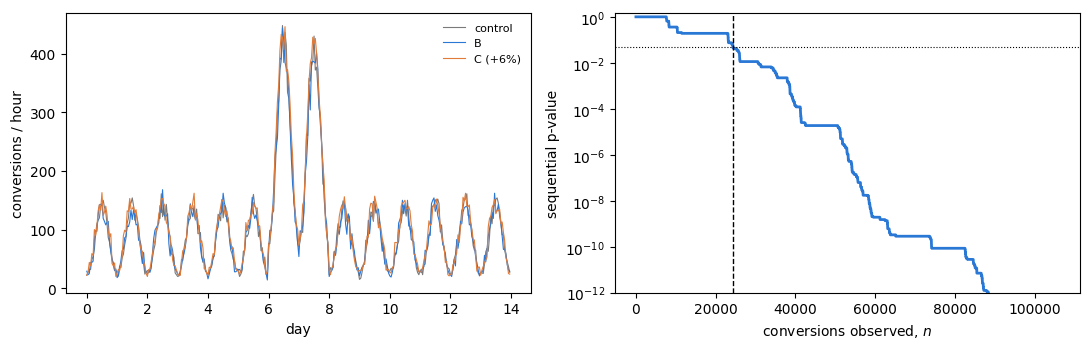

In [5]:
#| label: fig-seq-path
#| fig-cap: "Left: hourly conversions per arm. The baseline has a daily cycle and a two-day promotion. Right: the anytime-valid sequential p-value, computed from running counts. The test rejects at the dashed line."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for a, (name, col) in enumerate(zip(["control", "B", "C (+6%)"], ["#7a7a7a", "#2a78d6", "#e07b39"])):
    ax.plot(hours / 24, hourly[:, a], lw=0.8, color=col, label=name)
ax.set_xlabel("day")
ax.set_ylabel("conversions / hour")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.plot(np.arange(1, len(events) + 1), p_seq, color="#2a78d6", lw=2)
ax.axhline(u, color="k", lw=0.8, ls=":")
if stop is not None:
    ax.axvline(stop, color="k", lw=1, ls="--")
ax.set_yscale("log")
ax.set_ylim(1e-12, 1.5)
ax.set_xlabel("conversions observed, $n$")
ax.set_ylabel("sequential p-value")
plt.tight_layout()
plt.show()

## Type-I error when checking continuously

Because the statistic is a function of running counts, simulating many A/A experiments (all arms
identical, so any rejection is a false positive) is a cumulative sum. We check the anytime-valid test after
every event and a fixed-sample chi-square test after every 250 events, and record whether either ever
rejects at 0.05.

In [6]:
n_sims, n_events = 1000, 10_000
null_events = rng.integers(0, 3, size=(n_sims, n_events))
S_null = np.cumsum(np.eye(3, dtype=np.int32)[null_events], axis=1)            # (sim, n, 3)
p_null = np.minimum.accumulate(np.minimum(1, np.exp(-log_bf(S_null, theta0, alpha0))), axis=1)
peeks = S_null[:, 249::250, :]
expected = peeks.sum(-1, keepdims=True) / 3
chi_p = stats.chi2.sf((((peeks - expected) ** 2) / expected).sum(-1), df=2)
ever_bf, ever_chi = (p_null <= u).any(1), (chi_p <= u).any(1)
pd.DataFrame({"procedure": ["anytime-valid, every event", "chi-square, every 250 events"],
              "P(ever reject | null)": [ever_bf.mean(), ever_chi.mean()]})

,procedure,P(ever reject | null)
0,"anytime-valid, every event",0.038
1,"chi-square, every 250 events",0.312


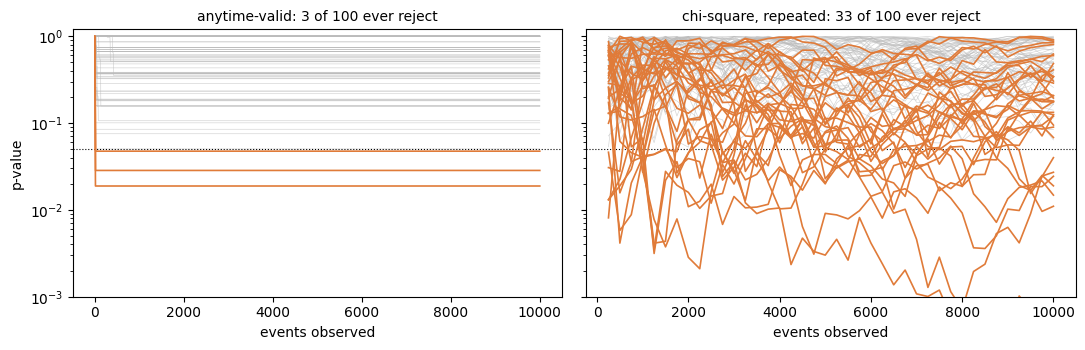

In [7]:
#| label: fig-seq-aa
#| fig-cap: "100 simulated A/A experiments. Left: anytime-valid p-values checked after every event. Right: chi-square p-values checked every 250 events. Paths that ever cross 0.05 (dotted line) are coloured; each is a false positive."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
x_peek = np.arange(250, n_events + 1, 250)
for ax, paths, xs, ever, title in [(axes[0], p_null[:100], np.arange(1, n_events + 1), ever_bf, "anytime-valid"),
                                   (axes[1], chi_p[:100], x_peek, ever_chi, "chi-square, repeated")]:
    for i, path in enumerate(paths):
        hit = ever[i]
        ax.plot(xs, path, lw=1.2 if hit else 0.5, color="#e07b39" if hit else "#bbbbbb",
                alpha=1 if hit else 0.6, zorder=3 if hit else 1)
    ax.axhline(u, color="k", lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 1.2)
    ax.set_xlabel("events observed")
    ax.set_title(f"{title}: {ever[:100].sum()} of 100 ever reject", fontsize=10)
axes[0].set_ylabel("p-value")
plt.tight_layout()
plt.show()

## How long a test runs

Stopping times are also cheap to simulate. For true lifts on arm C from 0% to 50% we simulate 300 event streams of
up to 60,000 events and record when each test first rejects. We repeat this for three mixing distributions
centred on $\boldsymbol\theta_0$, $\boldsymbol\alpha_0 = k\boldsymbol\theta_0$ with $k = 3$ (uniform), $30$ and
$300$. A larger $k$ concentrates the mixture near the null.

In [8]:
effects = [1.00, 1.02, 1.04, 1.06, 1.10, 1.25, 1.50]
ks = [3, 30, 300]
n_streams, horizon, batch = 300, 60_000, 50
stop_times = {(e, k): [] for e in effects for k in ks}
for e in effects:
    th = np.array([1, 1, e]) / (2 + e)
    for b in range(n_streams // batch):
        ev = (rng.random((batch, horizon))[..., None] > np.cumsum(th)[None, None, :]).sum(-1)
        Sb = np.cumsum(np.eye(3, dtype=np.int32)[ev], axis=1)
        for k in ks:
            hit = log_bf(Sb, theta0, k * theta0) >= np.log(1 / u)
            stop_times[(e, k)].extend(np.where(hit.any(1), hit.argmax(1) + 1, np.inf))
stop_times = {key: np.array(v) for key, v in stop_times.items()}

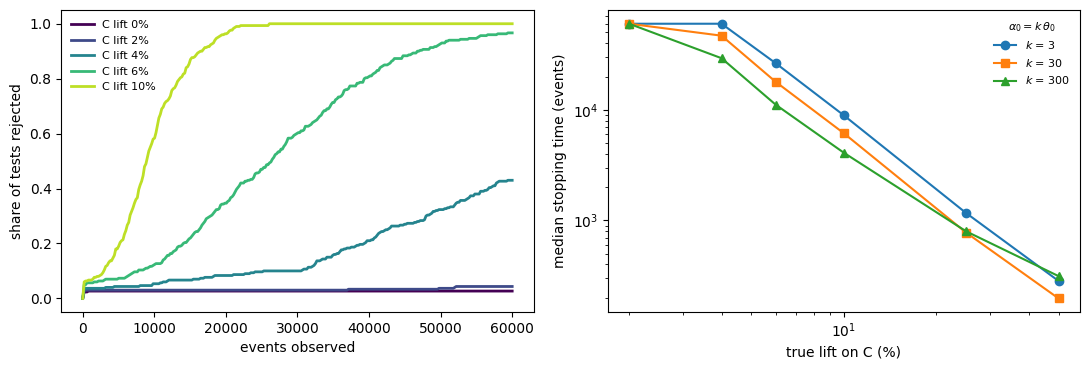

In [9]:
#| label: fig-seq-stop
#| fig-cap: "Left: share of 300 streams that have rejected by each event count, for different true lifts on arm C (uniform mixture). The 0% line is the false-positive rate. Right: median stopping time against true lift for three mixing distributions; streams that never reject within 60,000 events count as 60,000."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
left_effects = effects[:5]
cols = plt.cm.viridis(np.linspace(0, 0.9, len(left_effects)))
grid = np.linspace(0, horizon, 300)
for e, col in zip(left_effects, cols):
    t = stop_times[(e, 3)]
    ax.plot(grid, (t[:, None] <= grid[None, :]).mean(0), color=col, lw=2, label=f"C lift {100 * (e - 1):.0f}%")
ax.set_xlabel("events observed")
ax.set_ylabel("share of tests rejected")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
for k, mk in zip(ks, ["o", "s", "^"]):
    med = [np.median(np.minimum(stop_times[(e, k)], horizon)) for e in effects[1:]]
    ax.plot([100 * (e - 1) for e in effects[1:]], med, marker=mk, label=f"$k$ = {k}")
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_xlabel("true lift on C (%)")
ax.set_ylabel("median stopping time (events)")
ax.legend(frameon=False, fontsize=8, title=r"$\alpha_0 = k\,\theta_0$", title_fontsize=8)
plt.tight_layout()
plt.show()

## Estimation: one categorical per event vs one multinomial

For estimation we want the posterior for $\boldsymbol\theta$ and the rate ratios
$\rho_a/\rho_{\text{control}} = (\theta_a/\theta_{0,a})/(\theta_{\text{ctrl}}/\theta_{0,\text{ctrl}})$. The raw-data model
is a categorical likelihood over every event; the compressed one is a single multinomial on $\mathbf S_n$. The
conjugate posterior $\text{Dirichlet}(\boldsymbol\alpha_0 + \mathbf S_n)$ is shown for reference.

In [10]:
coords = {"arm": ["control", "B", "C"]}
n_final = S[-1]


def add_ratios(theta):
    pm.Deterministic("rate_ratio", (theta / theta0) / (theta[0] / theta0[0]), dims="arm")


with pm.Model(coords=coords) as cat_full:
    theta = pm.Dirichlet("theta", a=alpha0, dims="arm")
    add_ratios(theta)
    pm.Categorical("arm_of_event", p=theta, observed=events)

with pm.Model(coords=coords) as mult_suff:
    theta = pm.Dirichlet("theta", a=alpha0, dims="arm")
    add_ratios(theta)
    pm.Multinomial("S_n", n=n_final.sum(), p=theta, observed=n_final)

idata_full = timed_fit(cat_full, "Categorical, every event", len(events), "Sequential multinomial", "raw")
idata_suff = timed_fit(mult_suff, "Multinomial, S_n", 1, "Sequential multinomial", "compressed")
exact = rng.dirichlet(alpha0 + n_final, 20_000)
exact_ratio_C = (exact[:, 2] / theta0[2]) / (exact[:, 0] / theta0[0])

NUTS[nutpie]: [theta]
NUTS[nutpie]: [theta]


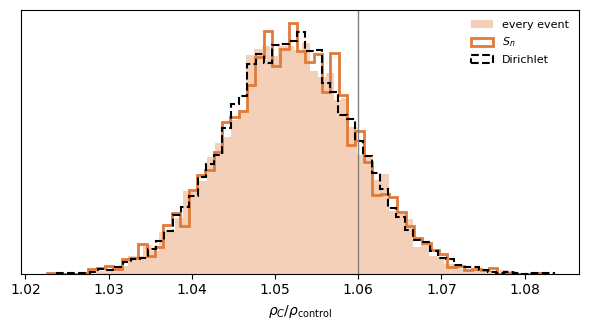

In [11]:
#| label: fig-seq-equiv
#| fig-cap: "Posterior rate ratio of arm C to control: every event (filled), running counts (line), conjugate Dirichlet (dashed). The grey line is the true ratio."
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(idata_full.posterior["rate_ratio"].sel(arm="C").values.ravel(), bins=60, density=True,
        alpha=0.35, color="#e07b39", label="every event")
ax.hist(idata_suff.posterior["rate_ratio"].sel(arm="C").values.ravel(), bins=60, density=True,
        histtype="step", lw=2, color="#e07b39", label="$S_n$")
ax.hist(exact_ratio_C, bins=60, density=True, histtype="step", lw=1.5, ls="--", color="k", label="Dirichlet")
ax.axvline(rho[2], color="grey", lw=1)
ax.set_yticks([])
ax.set_xlabel(r"$\rho_C / \rho_{\text{control}}$")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
#| label: tbl-seq-speed
#| tbl-cap: "Rows in the likelihood, wall time and minimum bulk ESS per second."
save_timings("02_sequential_multinomial")

,kind,model,rows,wall_s,min_ess_per_s
0,raw,"Categorical, every event",106072,5.15,409.9
1,compressed,"Multinomial, S_n",1,0.95,2115.4


## What compression gives up

Conditioning on events discards when they happened, which is why $\lambda(t)$ drops out. It also means the
total counts cannot show whether the effect changed over time. To ask that question, keep $\mathbf S$ per day.
The figure below computes the conjugate posterior for each day's counts separately.

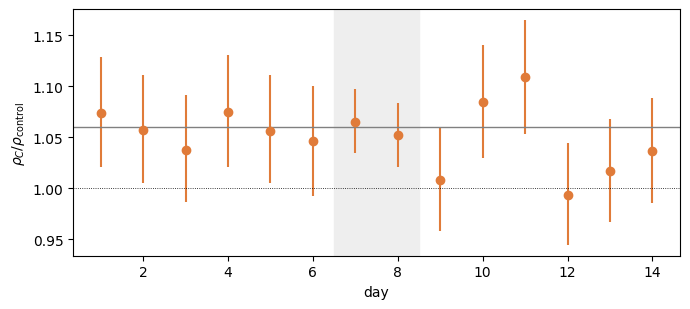

In [13]:
#| label: fig-seq-daily
#| fig-cap: "Posterior mean and 89% interval of the rate ratio of arm C to control, computed separately from each day's counts. The shaded days are the promotion. The grey line is the true ratio."
day_counts = hourly.reshape(14, 24, 3).sum(1)
day_draws = np.stack([rng.dirichlet(alpha0 + c, 20_000) for c in day_counts])     # (day, draw, arm)
ratios = day_draws[..., 2] / day_draws[..., 0]
lo, hi = np.quantile(ratios, [0.055, 0.945], axis=1)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvspan(6.5, 8.5, color="#eeeeee")
ax.errorbar(np.arange(1, 15), ratios.mean(1), yerr=[ratios.mean(1) - lo, hi - ratios.mean(1)], fmt="o", color="#e07b39")
ax.axhline(rho[2], color="grey", lw=1)
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xlabel("day")
ax.set_ylabel(r"$\rho_C / \rho_{\text{control}}$")
plt.tight_layout()
plt.show()

- The type-I guarantee does not depend on $\boldsymbol\alpha_0$, but stopping times do. In the stopping-time figure the
  mixture concentrated near $\boldsymbol\theta_0$ ($k = 300$) stops soonest for lifts up to 10%, and is the slowest of
  the three at a 50% lift.
- Per-period counts restore the time dimension at the cost of more numbers, and they still add up to $\mathbf S_n$.